# Стационарная теплопроводность

## 1. Постановка задачи

Работа объединяет исходное задание лабораторной работы и задачу размещения
обогревателей. Вся теория, вычисления, графики и проверки находятся в этой
тетради; запускать другие тетради не требуется.


### Задача А. Уравнение Лапласа в квадрате

Найти стационарное распределение температуры в квадратном сечении бесконечной балки:
$$u_{xx}+u_{yy}=0,\qquad 0<x<L,\quad 0<y<L,\quad L=0.1\text{ м}.$$
На AB (слева) задано $u=1$, на BC (сверху) — $u=2$,
на CD (справа) — $u=3$, на DA (снизу) — $u=4$.
Точка A находится в левом нижнем углу; $T=100u$ в градусах Цельсия.

Решить задачу методами Якоби, Зейделя и верхней релаксации (SOR), сравнить
скорость сходимости, построить изолинии и сечения температуры. Проверить
сгущение сетки по ряду Фурье и исследовать влияние параметра релаксации.

### Задача Б. Комната с тепловой надписью

В прямоугольной комнате заданы размеры и температуры четырёх стен.
Расположить обогреватели так, чтобы на рассчитанной карте температуры
читалась надпись **«РТ»**. При необходимости на стенах можно разместить окна.

Используем шесть прямоугольных нагревательных полос: четыре образуют «Р»,
две — «Т». Узлы обогревателей имеют заданную температуру; окно заменяет
температуру на выбранном участке стены. Дополнительно учитываем теплообмен
через пол и потолок:
$$-K\nabla^2T+H_{loss}(T-T_{ambient})=0.$$

Это учебная двумерная модель теплопроводности. Она не учитывает движение
воздуха, ограничения мощности обогревателей и трёхмерную геометрию комнаты.
Расположение полос задано явно; автоматический поиск оптимального размещения
не выполняется. Надпись получается из решения уравнения, без наложения текста
на итоговый график.

Исходное задание: [страница 1](materials/assignment_1.jpg),
[страница 2](materials/assignment_2.jpg).

## 2. Библиотеки и параметры

Все исходные данные задаются в следующих двух ячейках. После изменения
параметров выполните тетрадь сверху вниз. Имена параметров задачи А имеют
префикс `square_`, чтобы настройки двух задач не влияли друг на друга.

### Параметры задачи А

`square_length` — сторона квадрата; `square_left`, `square_top`,
`square_right`, `square_bottom` — граничные значения $u$;
`square_temperature_scale` — множитель перехода к температуре.
`square_intervals` задаёт число интервалов, `square_tolerance` — относительный
допуск, `square_max_iterations` — предел числа итераций.

In [1]:
from numbers import Integral

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# Edit the physical data and numerical settings here.
square_length = 0.1
square_temperature_scale = 100.0
square_left, square_top, square_right, square_bottom = 1.0, 2.0, 3.0, 4.0
square_intervals = 20
square_tolerance = 1e-9
square_max_iterations = 50000
square_methods = ["Jacobi", "Gauss-Seidel", "SOR"]

if not np.all(np.isfinite([square_length, square_temperature_scale, square_left, square_top, square_right, square_bottom])):
    raise ValueError("Physical parameters must be finite.")
if square_length <= 0 or square_temperature_scale <= 0:
    raise ValueError("Length and temperature scale must be positive.")

### Параметры задачи Б

`room` — словарь с размерами комнаты, температурами стен и окружающей среды,
теплопроводностью и коэффициентом потерь тепла. Длины задаются в метрах,
температуры — в градусах Цельсия. Начало координат находится в левом нижнем углу.

`heater_temperature` и `stroke_width` задают температуру и толщину полос.
При `custom_heaters = None` используется схема «РТ», при `[]` обогревателей нет.
Для своего размещения задайте список словарей с полями `name`, `x_min`,
`x_max`, `y_min`, `y_max`, `temperature`.

`windows` — список окон с полями `wall`, `start`, `end`, `temperature`.
Допустимые стены: `left`, `right`, `bottom`, `top`. Координата окна отсчитывается
вверх на вертикальной стене и вправо на горизонтальной. Значение `[]` отключает окна.

`nx`, `ny` — число интервалов по осям; `tolerance` — абсолютный допуск
нормированной невязки; `omega` — параметр SOR. Допуск задачи Б измеряется
в градусах Цельсия и отличается от относительного допуска задачи А.

Размеры схемы букв автоматически меняются вместе с комнатой, но толщина
полос, координаты окон и собственных обогревателей задаются в метрах.

In [2]:
# Physical settings for the room experiment.
room = dict(
    width=10.0, height=6.0,
    left=18.0, right=18.0, bottom=16.0, top=20.0,
    ambient=18.0,
    conductivity=1.0,  # Effective slice conductivity, W/K.
    heat_loss=3.0,  # Distributed heat transfer, W/(m^2 K).
)
heater_temperature = 65.0
stroke_width = 0.18
custom_heaters = None  # A list of rectangle dictionaries overrides the default layout.
# Example: custom_heaters = [dict(name="H1", x_min=1.0, x_max=1.4,
#                               y_min=1.0, y_max=2.0, temperature=65.0)]
windows = [
    dict(wall="bottom", start=0.7, end=2.2, temperature=5.0),
    dict(wall="top", start=7.4, end=9.3, temperature=5.0),
]

# nx and ny count intervals, not nodes.
nx, ny = 160, 96
tolerance = 1e-8  # Absolute diagonal-normalized residual, degrees C.
max_iterations = 30000
omega = 1.8

## 3. Теория и методы

### 3.1. Уравнение Лапласа в квадрате

#### Сетка и разностная схема

Используем равномерную сетку с $h_x=h_y=h=L/n$ и пятиузловую схему:
$$u_{j,i}=\frac{u_{j,i-1}+u_{j,i+1}+u_{j-1,i}+u_{j+1,i}}4.$$
В массиве первая координата — номер строки по y, вторая — по x.
Внутри области начальное приближение равно нулю; границы фиксированы.
В углах значения соседних сторон не согласованы: используем их среднее.
Угловые узлы не входят ни в одну схему для внутренних точек.

In [3]:
def square_initial_temperature(n):
    if not isinstance(n, int) or isinstance(n, bool) or n < 2:
        raise ValueError("The grid needs at least two intervals per side.")
    u = np.zeros((n + 1, n + 1))
    u[1:-1, 0], u[1:-1, -1] = square_left, square_right
    u[0, 1:-1], u[-1, 1:-1] = square_bottom, square_top
    # Corner averages are a plotting convention, not extra interior equations.
    u[0, 0], u[0, -1] = (square_bottom + square_left) / 2, (square_bottom + square_right) / 2
    u[-1, 0], u[-1, -1] = (square_top + square_left) / 2, (square_top + square_right) / 2
    return u

def square_neighbor_average(u):
    return (u[1:-1, :-2] + u[1:-1, 2:] + u[:-2, 1:-1] + u[2:, 1:-1]) / 4

def square_residual_norm(u):
    # Divide the discrete Laplace operator by its diagonal coefficient.
    return np.max(np.abs(square_neighbor_average(u) - u[1:-1, 1:-1]))

#### Метод Якоби

Все новые значения вычисляются по предыдущей итерации:
$$u_{j,i}^{(k+1)}=\frac{u_{j,i-1}^{(k)}+u_{j,i+1}^{(k)}
+u_{j-1,i}^{(k)}+u_{j+1,i}^{(k)}}4.$$
NumPy сначала вычисляет правую часть целиком, поэтому присваивание
внутри массива не смешивает старые и новые значения.

In [4]:
def jacobi_step(u):
    # The array expression is evaluated before the interior is overwritten.
    u[1:-1, 1:-1] = square_neighbor_average(u)

#### Метод Зейделя

Обходим узлы последовательно. Левый и нижний соседи уже обновлены:
$$u_{j,i}^{(k+1)}=\frac{u_{j,i-1}^{(k+1)}+u_{j-1,i}^{(k+1)}
+u_{j,i+1}^{(k)}+u_{j+1,i}^{(k)}}4.$$

In [5]:
def seidel_step(u):
    for j in range(1, u.shape[0] - 1):
        for i in range(1, u.shape[1] - 1):
            # Updated left/lower values are used immediately.
            u[j, i] = (u[j, i - 1] + u[j, i + 1] + u[j - 1, i] + u[j + 1, i]) / 4

#### Метод верхней релаксации (SOR)

Смешиваем старое значение и результат шага Зейделя $\overline u$:
$$u_{j,i}^{(k+1)}=u_{j,i}^{(k)}+\omega(\overline u_{j,i}-u_{j,i}^{(k)}).$$
Здесь $\omega$ соответствует $\tau$ из задания. При $\omega=1$ получаем
метод Зейделя; верхняя релаксация использует $1<\omega<2$.

In [6]:
def sor_step(u, omega):
    for j in range(1, u.shape[0] - 1):
        for i in range(1, u.shape[1] - 1):
            average = (u[j, i - 1] + u[j, i + 1] + u[j - 1, i] + u[j + 1, i]) / 4
            u[j, i] += omega * (average - u[j, i])

#### Общий цикл итераций и теоретическая скорость

Критерий остановки одинаков для трёх методов:
$\|b-Au\|_\infty/\|b\|_\infty\leq \texttt{square\_tolerance}$.
При нулевом начальном приближении знаменатель равен начальной невязке.
Для нулевой правой части используем абсолютную невязку.

На квадратной сетке $\rho_J=\cos(\pi/n)$, $\rho_{GS}=\rho_J^2$.
Оптимальный параметр $\omega_{opt}=2/(1+\sin(\pi/n))$, а
$\rho_{SOR}(\omega_{opt})=\omega_{opt}-1$.
Чем меньше спектральный радиус, тем быстрее асимптотическая сходимость.
При фиксированном уменьшении ошибки Якоби и Зейделю требуется порядка
$O(n^2)$ итераций, оптимальному SOR — порядка $O(n)$.

In [7]:
def optimal_omega(n):
    return 2 / (1 + np.sin(np.pi / n))

def spectral_radius(n, method, omega=1.0):
    rho = np.cos(np.pi / n)
    if method == "Jacobi":
        return rho
    if method == "Gauss-Seidel":
        return rho**2
    discriminant = omega**2 * rho**2 - 4 * (omega - 1)
    if discriminant <= 0:
        return omega - 1
    return ((omega * rho + np.sqrt(discriminant)) / 2)**2

def solve_square_heat(n, method, omega=1.0, tol=square_tolerance, limit=square_max_iterations):
    if method not in square_methods:
        raise ValueError("Unknown heat solver method.")
    if not np.isfinite(tol) or not 0 < tol < 1:
        raise ValueError("Tolerance must be between zero and one.")
    if isinstance(limit, bool) or not isinstance(limit, Integral) or limit < 1:
        raise ValueError("The iteration limit must be a positive integer.")
    if method == "SOR" and (not np.isfinite(omega) or not 1 <= omega < 2):
        raise ValueError("SOR requires 1 <= omega < 2.")
    u = square_initial_temperature(n)
    residual = square_residual_norm(u)
    scale = residual or 1.0
    history = [residual / scale]
    if history[0] <= tol:
        return u, history
    for _ in range(limit):
        if method == "Jacobi":
            jacobi_step(u)
        elif method == "Gauss-Seidel":
            seidel_step(u)
        else:
            sor_step(u, omega)
        value = square_residual_norm(u) / scale
        if not np.isfinite(value):
            raise ArithmeticError("The heat equation residual is not finite.")
        history.append(value)
        if value <= tol:
            return u, history
    raise RuntimeError(f"{method} reached the iteration limit.")

### 3.2. Комната, обогреватели и окна

В задаче А температура изменяется только из-за заданных значений на внешней
границе. В задаче Б появляются внутренние границы — обогреватели — и
распределённый теплообмен с окружающей средой. При `room['heat_loss'] = 0`
получаем уравнение Лапласа, но уже в комнате с внутренними препятствиями.

$K$ — эффективная теплопроводность, проинтегрированная по толщине слоя,
в Вт/К; $H_{loss}$ — коэффициент теплообмена на единицу площади пола,
в Вт/(м²·К). Члены уравнения имеют размерность Вт/м².

#### Геометрия и граничные условия

Функция `make_letter_heaters` создаёт шесть прямоугольных полос.
`build_heat_grid` строит сетку и маски фиксированных узлов. Окна заменяют
значения на соответствующих участках стен; обогреватели находятся строго
внутри комнаты. В углах внешней границы используем среднее температур
соседних стен. Эти углы не входят во внутренний пятиузловой шаблон.

Пересечения обогревателей с одинаковой температурой разрешены. Если два
объекта требуют разных температур в одном узле, расчёт останавливается
с ошибкой. Окно или обогреватель, не содержащие ни одного узла сетки, также
вызывают ошибку: нужно уменьшить шаг или увеличить размер объекта.

In [8]:
def make_letter_heaters(room, temperature, thickness):
    width, height = room["width"], room["height"]
    if not np.isfinite(thickness) or not 0 < thickness < 0.12 * min(width, height):
        raise ValueError("Stroke width must be positive and smaller than 12% of the shorter wall.")

    # Each segment stores its name and normalized start/end coordinates.
    segments = [
        ("P stem", 0.18, 0.18, 0.18, 0.82),
        ("P top", 0.18, 0.43, 0.82, 0.82),
        ("P middle", 0.18, 0.43, 0.51, 0.51),
        ("P bowl", 0.43, 0.43, 0.51, 0.82),
        ("T top", 0.57, 0.84, 0.82, 0.82),
        ("T stem", 0.705, 0.705, 0.18, 0.82),
    ]
    half = thickness / 2
    return [dict(name=name, x_min=x0 * width - half, x_max=x1 * width + half,
                 y_min=y0 * height - half, y_max=y1 * height + half,
                 temperature=temperature)
            for name, x0, x1, y0, y1 in segments]

In [9]:
def place_fixed_feature(grid, mask, temperature, occupied, kind):
    if not mask.any():
        raise ValueError(f"{kind} misses all grid nodes; refine the grid or enlarge the feature.")
    overlap = mask & occupied
    if np.any(grid['values'][overlap] != temperature):
        raise ValueError(f"{kind} overlaps another feature with a different temperature.")
    grid['values'][mask] = temperature
    grid['fixed'][mask] = True
    occupied[mask] = True


def add_window_to_grid(grid, window):
    if window['wall'] not in ("left", "right", "bottom", "top"):
        raise ValueError("Window wall must be left, right, bottom, or top.")
    vertical = window['wall'] in ("left", "right")
    coordinates = grid['y'] if vertical else grid['x']
    if not np.all(np.isfinite([window['start'], window['end'], window['temperature']])):
        raise ValueError("Window parameters must be finite.")
    if not 0 < window['start'] < window['end'] < coordinates[-1]:
        raise ValueError("A window must lie strictly within its wall, excluding corners.")
    selected = (coordinates >= window['start']) & (coordinates <= window['end'])
    mask = np.zeros_like(grid['fixed'])
    if vertical:
        mask[:, 0 if window['wall'] == "left" else -1] = selected
    else:
        mask[0 if window['wall'] == "bottom" else -1, :] = selected
    place_fixed_feature(grid, mask, window['temperature'], grid['window_mask'], "Window")


def add_heater_to_grid(grid, heater):
    values = [heater['x_min'], heater['x_max'], heater['y_min'],
              heater['y_max'], heater['temperature']]
    if not np.all(np.isfinite(values)):
        raise ValueError("Heater parameters must be finite.")
    if not (0 < heater['x_min'] < heater['x_max'] < grid['room']['width']
            and 0 < heater['y_min'] < heater['y_max'] < grid['room']['height']):
        raise ValueError("Each heater must be a rectangle strictly inside the room.")
    mask = ((grid['x'][None, :] >= heater['x_min']) & (grid['x'][None, :] <= heater['x_max'])
            & (grid['y'][:, None] >= heater['y_min']) & (grid['y'][:, None] <= heater['y_max']))
    place_fixed_feature(grid, mask, heater['temperature'], grid['heater_mask'], "Heater")


def build_heat_grid(room, nx, ny, heaters=(), windows=()):
    physical = [room['width'], room['height'], room['left'], room['right'],
                room['bottom'], room['top'], room['ambient'],
                room['conductivity'], room['heat_loss']]
    if not np.all(np.isfinite(physical)):
        raise ValueError("Room parameters must be finite.")
    if min(room['width'], room['height'], room['conductivity']) <= 0 or room['heat_loss'] < 0:
        raise ValueError("Dimensions and conductivity must be positive; heat loss must be nonnegative.")
    if any(isinstance(n, bool) or not isinstance(n, Integral) or n < 2 for n in (nx, ny)):
        raise ValueError("Each grid direction needs at least two integer intervals.")
    x = np.linspace(0, room["width"], nx + 1)
    y = np.linspace(0, room["height"], ny + 1)
    values = np.full((ny + 1, nx + 1), room["ambient"], dtype=float)
    fixed = np.zeros_like(values, dtype=bool)
    fixed[[0, -1], :] = fixed[:, [0, -1]] = True
    left, right, bottom, top = (room[wall] for wall in ("left", "right", "bottom", "top"))
    values[1:-1, 0], values[1:-1, -1] = left, right
    values[0, 1:-1], values[-1, 1:-1] = bottom, top
    # Corner averages only affect plotting, not the interior stencil.
    values[0, 0], values[0, -1] = (left + bottom) / 2, (right + bottom) / 2
    values[-1, 0], values[-1, -1] = (left + top) / 2, (right + top) / 2
    grid = dict(room=room.copy(), x=x, y=y, dx=room["width"] / nx, dy=room["height"] / ny,
                values=values, fixed=fixed, heater_mask=np.zeros_like(fixed),
                window_mask=np.zeros_like(fixed))
    for window in windows:
        add_window_to_grid(grid, window)
    for heater in heaters:
        add_heater_to_grid(grid, heater)
    grid['free'] = ~grid['fixed'][1:-1, 1:-1]
    if not grid['free'].any():
        raise ValueError("The grid must contain at least one free interior node.")
    grid['ax'] = room['conductivity'] / grid['dx']**2
    grid['ay'] = room['conductivity'] / grid['dy']**2
    grid['diagonal'] = 2 * (grid['ax'] + grid['ay']) + room['heat_loss']
    return grid

#### Разностная схема и итерационные методы

Сетка может иметь разные шаги $\Delta x$ и $\Delta y$. Обозначим
$a_x=K/\Delta x^2$, $a_y=K/\Delta y^2$ и $d=2a_x+2a_y+H_{loss}$.
Для свободного узла:
$$\overline T_{j,i}=\frac{
a_x(T_{j,i-1}+T_{j,i+1})+a_y(T_{j-1,i}+T_{j+1,i})+
H_{loss}T_{ambient}}{d}.$$

Якоби одновременно обновляет все свободные узлы по предыдущей итерации.
В методе Зейделя здесь используем шахматный обход: сначала обновляем узлы
одного цвета, затем другого. У узлов одного цвета нет общих рёбер, поэтому
их можно обновлять одновременно средствами NumPy. В задаче А сохранён
исходный последовательный обход; обе схемы решают одну разностную систему.

Для SOR применяем $T\leftarrow T+\omega(\overline T-T)$ с тем же шахматным
обходом. При $\omega=1$ получаем метод Зейделя. Фиксированные узлы стен,
окон и обогревателей в обновлении не участвуют.

Критерий остановки: $\max_{free}|\overline T-T|\leq tolerance$.
Это абсолютная невязка, делённая на диагональный коэффициент, в градусах
Цельсия; она не является непосредственной оценкой ошибки температуры.
Невязка исходного уравнения равна $d$-кратному значению этого критерия.
При превышении лимита итераций решатель сообщает об ошибке.

Формула оптимального параметра SOR для чистого квадрата из задачи А
не переносится напрямую на комнату с внутренними границами и потерями тепла.

In [10]:
def room_neighbor_average(grid, temperature):
    return (grid['ax'] * (temperature[1:-1, :-2] + temperature[1:-1, 2:])
            + grid['ay'] * (temperature[:-2, 1:-1] + temperature[2:, 1:-1])
            + grid['room']['heat_loss'] * grid['room']['ambient']) / grid['diagonal']


def room_residual_norm(grid, temperature):
    defect = room_neighbor_average(grid, temperature) - temperature[1:-1, 1:-1]
    return float(np.max(np.abs(defect[grid['free']])))

In [11]:
def solve_room_heat(grid, method="SOR", omega=1.8, tol=1e-8, limit=30000):
    if method not in ("Jacobi", "Gauss-Seidel", "SOR"):
        raise ValueError("Unknown heat solver method.")
    if not np.isfinite(tol) or tol <= 0:
        raise ValueError("Tolerance must be finite and positive.")
    if isinstance(limit, bool) or not isinstance(limit, Integral) or limit < 1:
        raise ValueError("Iteration limit must be a positive integer.")
    if method == "SOR" and (not np.isfinite(omega) or not 0 < omega < 2):
        raise ValueError("SOR requires 0 < omega < 2.")

    temperature = grid['values'].copy()
    interior = temperature[1:-1, 1:-1]
    parity = np.indices(interior.shape).sum(axis=0) % 2
    colors = [(parity == color) & grid['free'] for color in (0, 1)]
    relaxation = omega if method == "SOR" else 1.0
    history = [room_residual_norm(grid, temperature)]
    if history[-1] <= tol:
        return temperature, np.asarray(history)

    for _ in range(limit):
        if method == "Jacobi":
            average = room_neighbor_average(grid, temperature)
            interior[grid['free']] = average[grid['free']]
        else:
            for selected in colors:
                average = room_neighbor_average(grid, temperature)
                interior[selected] += relaxation * (average[selected] - interior[selected])
        residual = room_residual_norm(grid, temperature)
        if not np.isfinite(residual):
            raise ArithmeticError("The heat equation residual is not finite.")
        history.append(residual)
        if residual <= tol:
            return temperature, np.asarray(history)
    raise RuntimeError(f"{method} did not converge after {limit} iterations; residual={history[-1]:.3e}.")

## 4. Расчёты и графики

### 4.1. Уравнение Лапласа в квадрате

#### Сравнение методов

Используем одну сетку, одно начальное приближение и одинаковый допуск.
Сравниваем число итераций, а не время Python-циклов с операциями NumPy.
Для SOR берём теоретически оптимальный параметр.

Method          Iterations   Relative residual   Theoretical rho
Jacobi             1385      9.980e-10          0.987688
Gauss-Seidel        694      9.995e-10          0.975528
SOR                  80      5.519e-10          0.729454


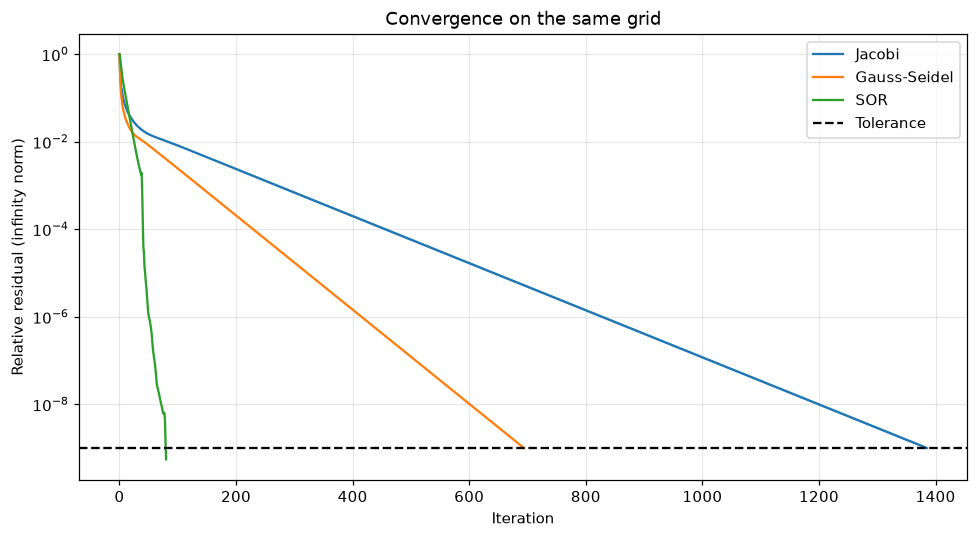

In [12]:
solutions, histories = {}, {}
square_omega = optimal_omega(square_intervals)
print("Method          Iterations   Relative residual   Theoretical rho")
for method in square_methods:
    u, history = solve_square_heat(square_intervals, method, square_omega)
    solutions[method], histories[method] = u, history
    print(f"{method:14s} {len(history)-1:8d}      {history[-1]:.3e}          "
          f"{spectral_radius(square_intervals, method, square_omega):.6f}")

fig, ax = plt.subplots(figsize=(9, 5))
for method in square_methods:
    values = np.asarray(histories[method])
    ax.semilogy(np.where(values > 0, values, np.nan), label=method)
ax.axhline(square_tolerance, color="black", linestyle="--", label="Tolerance")
ax.set_xlabel("Iteration")
ax.set_ylabel("Relative residual (infinity norm)")
ax.set_title("Convergence on the same grid")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

#### Изолинии и сечения температуры

Решения методов должны совпадать с точностью итерационного допуска.
Для рисунков используем SOR и переводим относительные значения в градусы:
$T=100u$. Сечения выбираются приблизительно на четверти, половине
и трёх четвертях стороны; в легенде указана фактическая координата узла.

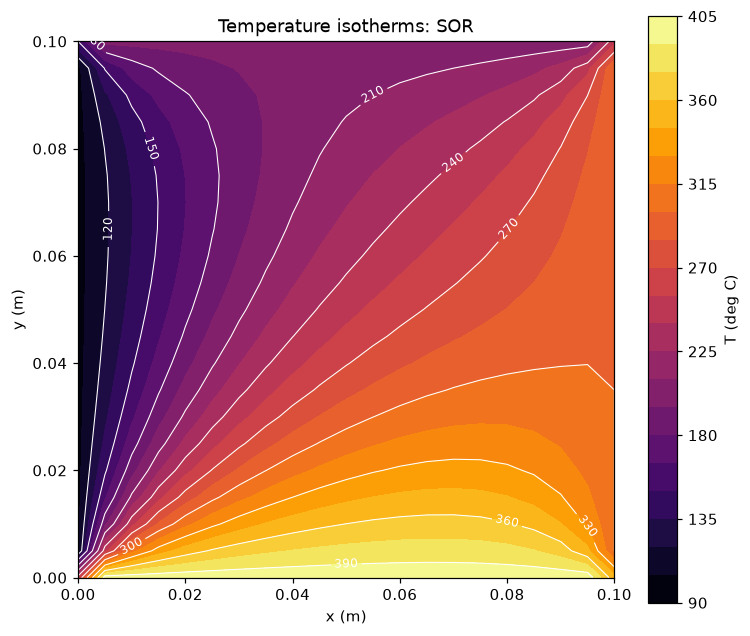

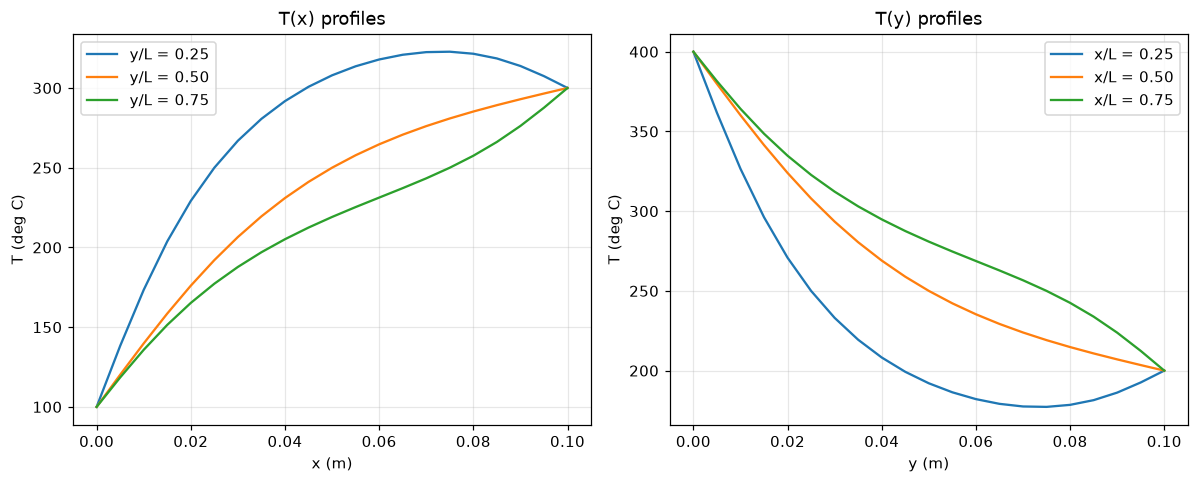

In [13]:
coordinates = np.linspace(0, square_length, square_intervals + 1)
square_temperature = solutions["SOR"] * square_temperature_scale
fig, ax = plt.subplots(figsize=(7, 6))
filled = ax.contourf(coordinates, coordinates, square_temperature, levels=24, cmap="inferno")
lines = ax.contour(coordinates, coordinates, square_temperature, levels=10, colors="white", linewidths=0.7)
ax.clabel(lines, fmt="%.0f", fontsize=8)
fig.colorbar(filled, ax=ax, label="T (deg C)")
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Temperature isotherms: SOR")
ax.set_aspect("equal")
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
indices = sorted({max(1, min(square_intervals - 1, round(fraction * square_intervals)))
                  for fraction in (0.25, 0.5, 0.75)})
for index in indices:
    position = coordinates[index] / square_length
    axes[0].plot(coordinates, square_temperature[index, :], label=f"y/L = {position:.2f}")
    axes[1].plot(coordinates, square_temperature[:, index], label=f"x/L = {position:.2f}")
for ax, coordinate in zip(axes, ("x", "y")):
    ax.set_xlabel(f"{coordinate} (m)")
    ax.set_ylabel("T (deg C)")
    ax.set_title(f"T({coordinate}) profiles")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

#### Проверка сходимости по сетке

Для независимой проверки используем ряд Фурье — сумму вкладов четырёх
сторон. Например, вклад левой стороны равен
$$\sum_{k=1,3,5,\ldots}\frac{4u_{left}}{k\pi}
\sin\frac{k\pi y}{L}\frac{\sinh(k\pi(1-x/L))}{\sinh(k\pi)}.$$
Остальные вклады получаются поворотом координат.

Берём 100 нечётных гармоник и измеряем максимальную ошибку в
$[0.2L,0.8L]^2$, вдали от разрывов в углах. При сгущении сетки ожидается
порядок $p=\log_2(E_h/E_{h/2})$, приближающийся к 2.

Method          Intervals   Maximum error (deg C)   Order
Jacobi               10      7.747059e-01              n/a
Gauss-Seidel         10      7.747061e-01              n/a
SOR                  10      7.747045e-01              n/a
Jacobi               20      2.200355e-01              1.816
Gauss-Seidel         20      2.200362e-01              1.816
SOR                  20      2.200286e-01              1.816
Jacobi               40      5.699617e-02              1.949
Gauss-Seidel         40      5.699772e-02              1.949
SOR                  40      5.696840e-02              1.949


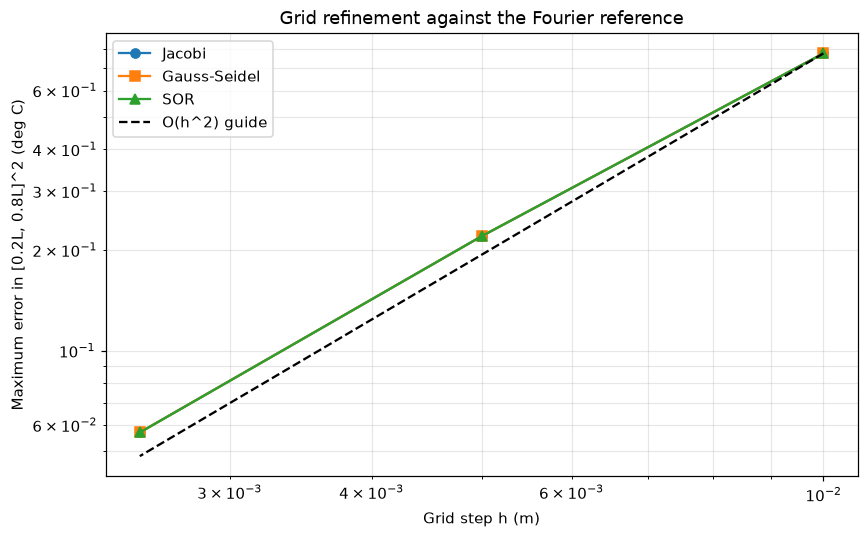

In [14]:
def fourier_reference(x, y):
    x, y = np.asarray(x) / square_length, np.asarray(y) / square_length
    u = np.zeros(np.broadcast_shapes(x.shape, y.shape))
    # The largest sinh argument is 199*pi, safely below float64 overflow.
    for k in range(1, 200, 2):
        a = k * np.pi
        from_left = square_left * np.sin(a * y) * np.sinh(a * (1 - x)) / np.sinh(a)
        from_right = square_right * np.sin(a * y) * np.sinh(a * x) / np.sinh(a)
        from_bottom = square_bottom * np.sin(a * x) * np.sinh(a * (1 - y)) / np.sinh(a)
        from_top = square_top * np.sin(a * x) * np.sinh(a * y) / np.sinh(a)
        u += 4 / a * (from_left + from_right + from_bottom + from_top)
    return u

grid_sizes = [10, 20, 40]
grid_errors = {method: [] for method in square_methods}
print("Method          Intervals   Maximum error (deg C)   Order")
for n in grid_sizes:
    axis = np.linspace(0, square_length, n + 1)
    indices = np.arange(n // 5, 4 * n // 5 + 1)
    x, y = np.meshgrid(axis[indices], axis[indices])
    exact = fourier_reference(x, y)
    for method in square_methods:
        if n == square_intervals:
            u = solutions[method]
        else:
            u, _ = solve_square_heat(n, method, optimal_omega(n))
        error = np.max(np.abs(u[np.ix_(indices, indices)] - exact)) * square_temperature_scale
        previous = grid_errors[method]
        order = np.log2(previous[-1] / error) if previous and error > 0 else None
        previous.append(error)
        order_text = f"{order:.3f}" if order is not None else "n/a"
        print(f"{method:14s} {n:8d}      {error:.6e}              {order_text}")

fig, ax = plt.subplots(figsize=(8, 5))
steps = square_length / np.array(grid_sizes)
for method, marker in zip(square_methods, ("o", "s", "^")):
    ax.loglog(steps, grid_errors[method], marker=marker, label=method)
ax.loglog(steps, grid_errors["SOR"][0] * (steps / steps[0])**2, "k--", label="O(h^2) guide")
ax.set_xlabel("Grid step h (m)")
ax.set_ylabel("Maximum error in [0.2L, 0.8L]^2 (deg C)")
ax.set_title("Grid refinement against the Fourier reference")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

#### Влияние параметра релаксации

Перебираем несколько $\omega\in[1,2)$ и добавляем теоретический оптимум.
При слишком большом параметре число итераций снова растёт.
Минимум числа итераций для конечного допуска может немного отличаться
от минимума асимптотического спектрального радиуса.

Theoretical optimum: 1.72945382
Best sampled omega: 1.72945382; iterations: 80


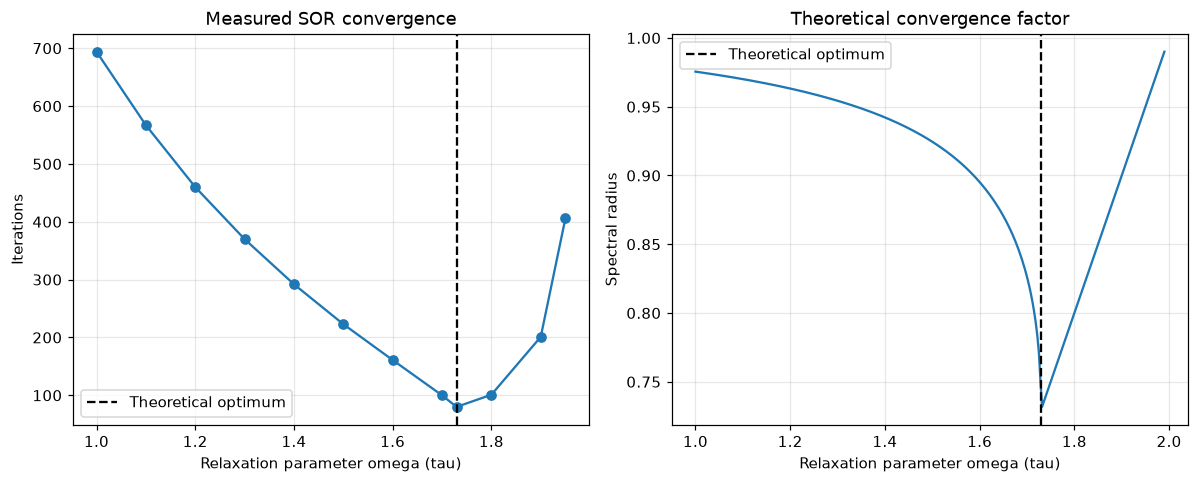

In [15]:
omega_values = sorted([1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 1.95, square_omega])
iteration_counts = []
for value in omega_values:
    _, history = solve_square_heat(square_intervals, "SOR", value)
    count = len(history) - 1
    iteration_counts.append(count)
best_index = np.argmin(iteration_counts)
print(f"Theoretical optimum: {square_omega:.8f}")
print(f"Best sampled omega: {omega_values[best_index]:.8f}; "
      f"iterations: {iteration_counts[best_index]}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(omega_values, iteration_counts, "o-")
axes[0].set_ylabel("Iterations")
axes[0].set_title("Measured SOR convergence")
dense_omega = np.linspace(1, 1.99, 300)
axes[1].plot(dense_omega, [spectral_radius(square_intervals, "SOR", value) for value in dense_omega])
axes[1].set_ylabel("Spectral radius")
axes[1].set_title("Theoretical convergence factor")
for ax in axes:
    ax.axvline(square_omega, color="black", linestyle="--", label="Theoretical optimum")
    ax.set_xlabel("Relaxation parameter omega (tau)")
    ax.grid(True, alpha=0.3)
    ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

### 4.2. Тепловая надпись в комнате

#### Расположение оборудования и решение

Сначала выводим размеры комнаты, параметры сетки, координаты обогревателей
и невязку. Отдельный рисунок показывает оборудование. Итоговая карта
температуры строится только по найденному решению, без текстовых надписей
и контуров букв поверх поля. На осях используются метры и одинаковый масштаб.

Room: 10 x 6 m; grid: 161 x 97 nodes
Grid spacing: dx=0.0625 m, dy=0.0625 m
Heaters: 6; windows: 2
SOR iterations: 197
Normalized residual: 9.184e-09 deg C
Equation residual: 9.432e-06 W/m^2
Temperature range: 5.00 to 65.00 deg C
Diffusion length: 0.577 m
Heater          x range (m)       y range (m)       Temperature (deg C)
P stem          1.71.. 1.89       0.99.. 5.01        65.0
P top           1.71.. 4.39       4.83.. 5.01        65.0
P middle        1.71.. 4.39       2.97.. 3.15        65.0
P bowl          4.21.. 4.39       2.97.. 5.01        65.0
T top           5.61.. 8.49       4.83.. 5.01        65.0
T stem          6.96.. 7.14       0.99.. 5.01        65.0


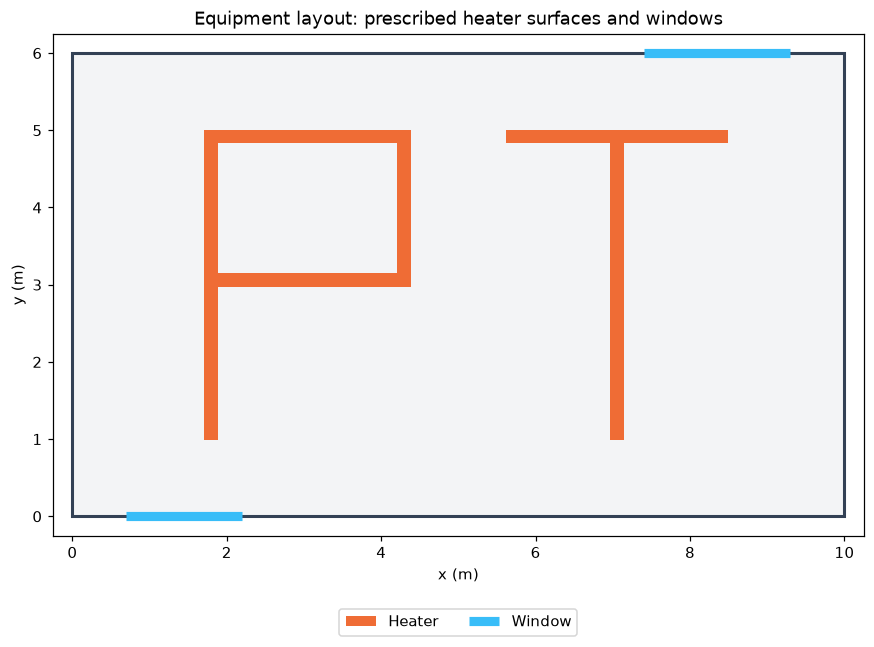

In [16]:
heaters = (make_letter_heaters(room, heater_temperature, stroke_width)
           if custom_heaters is None else list(custom_heaters))
grid = build_heat_grid(room, nx, ny, heaters, windows)
temperature, history = solve_room_heat(grid, omega=omega, tol=tolerance, limit=max_iterations)

print(f"Room: {room['width']:g} x {room['height']:g} m; grid: {nx + 1} x {ny + 1} nodes")
print(f"Grid spacing: dx={grid['dx']:.4f} m, dy={grid['dy']:.4f} m")
print(f"Heaters: {len(heaters)}; windows: {len(windows)}")
print(f"SOR iterations: {len(history) - 1}")
print(f"Normalized residual: {history[-1]:.3e} deg C")
print(f"Equation residual: {grid['diagonal'] * history[-1]:.3e} W/m^2")
print(f"Temperature range: {temperature.min():.2f} to {temperature.max():.2f} deg C")
if room['heat_loss'] > 0:
    print(f"Diffusion length: {np.sqrt(room['conductivity'] / room['heat_loss']):.3f} m")
print("Heater          x range (m)       y range (m)       Temperature (deg C)")
for heater in heaters:
    print(f"{heater['name']:14s} {heater['x_min']:5.2f}..{heater['x_max']:5.2f}      "
          f"{heater['y_min']:5.2f}..{heater['y_max']:5.2f}      {heater['temperature']:6.1f}")

fig, ax = plt.subplots(figsize=(10, 6))
ax.add_patch(Rectangle((0, 0), room['width'], room['height'],
                       facecolor="#f3f4f6", edgecolor="#334155", linewidth=2))
for index, heater in enumerate(heaters):
    ax.add_patch(Rectangle((heater['x_min'], heater['y_min']),
                           heater['x_max'] - heater['x_min'], heater['y_max'] - heater['y_min'],
                           facecolor="#ef6c35", label="Heater" if index == 0 else None))
for index, window in enumerate(windows):
    if window['wall'] in ("left", "right"):
        x = 0 if window['wall'] == "left" else room['width']
        xs, ys = [x, x], [window['start'], window['end']]
    else:
        y = 0 if window['wall'] == "bottom" else room['height']
        xs, ys = [window['start'], window['end']], [y, y]
    ax.plot(xs, ys, color="#38bdf8", linewidth=6,
            solid_capstyle="butt", label="Window" if index == 0 else None)
ax.set(xlim=(-0.25, room['width'] + 0.25), ylim=(-0.25, room['height'] + 0.25),
       xlabel="x (m)", ylabel="y (m)", title="Equipment layout: prescribed heater surfaces and windows")
ax.set_aspect("equal")
if heaters or windows:
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)
fig.tight_layout()
plt.show()
plt.close(fig)

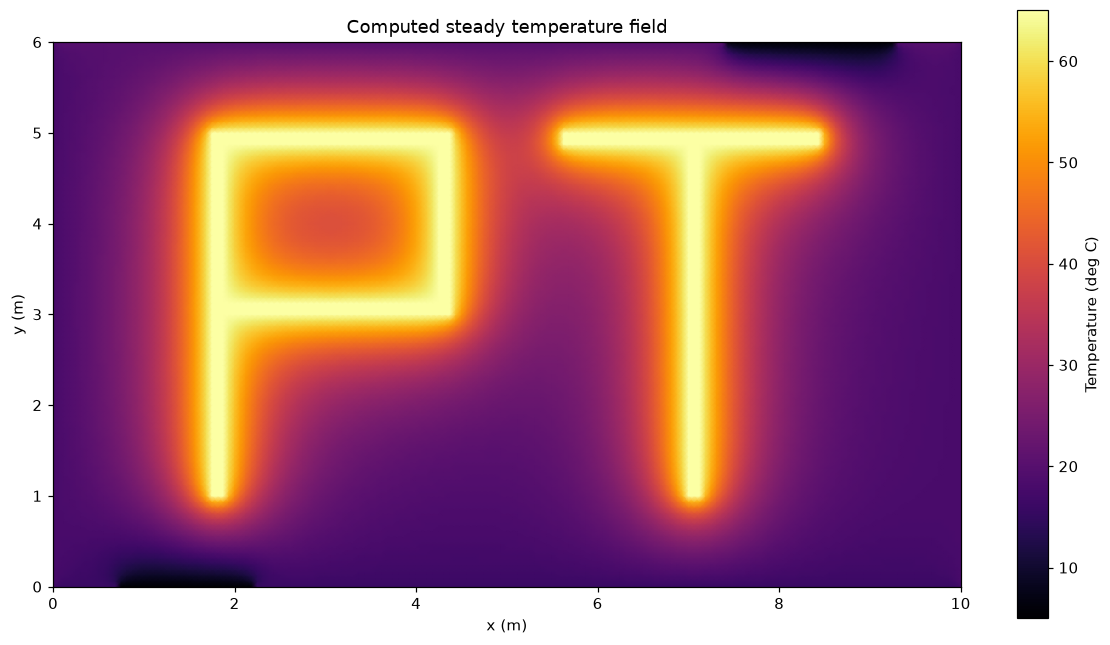

In [17]:
fixed_temperatures = grid['values'][grid['fixed']]
color_min = min(float(fixed_temperatures.min()), room['ambient'])
color_max = max(float(fixed_temperatures.max()), room['ambient'])
if color_max == color_min:
    color_min, color_max = color_min - 0.5, color_max + 0.5


def draw_temperature(ax, grid, field, title, limits):
    image = ax.pcolormesh(grid['x'], grid['y'], field, shading="gouraud",
                         cmap="inferno", vmin=limits[0], vmax=limits[1])
    ax.set(xlabel="x (m)", ylabel="y (m)", title=title)
    ax.set_aspect("equal")
    return image


fig, ax = plt.subplots(figsize=(11, 6.8))
color_limits = (color_min, color_max)
image = draw_temperature(
    ax, grid, temperature, "Computed steady temperature field", color_limits)
fig.colorbar(image, ax=ax, label="Temperature (deg C)", shrink=0.85)
fig.tight_layout()
plt.show()
plt.close(fig)

#### Влияние потерь тепла

Характерная длина распространения тепла равна
$\ell=\sqrt{K/H_{loss}}$. При уменьшении этой длины нагрев становится
более локальным, и буквы лучше различимы.

В замкнутой верхней части «Р» без потерь тепла устанавливается почти
температура обогревателя: холодные окна на внешних стенах не могут охладить
область, полностью окружённую нагревательными полосами, в рамках этой
двумерной модели. Теплообмен через пол и потолок сохраняет просвет буквы.

На общей цветовой шкале сравним комнату без обогревателей, вариант без
распределённых потерь и вариант с заданными потерями. При `room['heat_loss'] = 0`
последние два решения совпадут. Читаемость зависит от температуры стен,
расположения полос и выбранных коэффициентов; для произвольных данных
она не гарантируется. Ниже также приведены сходимость SOR и сечения поля.

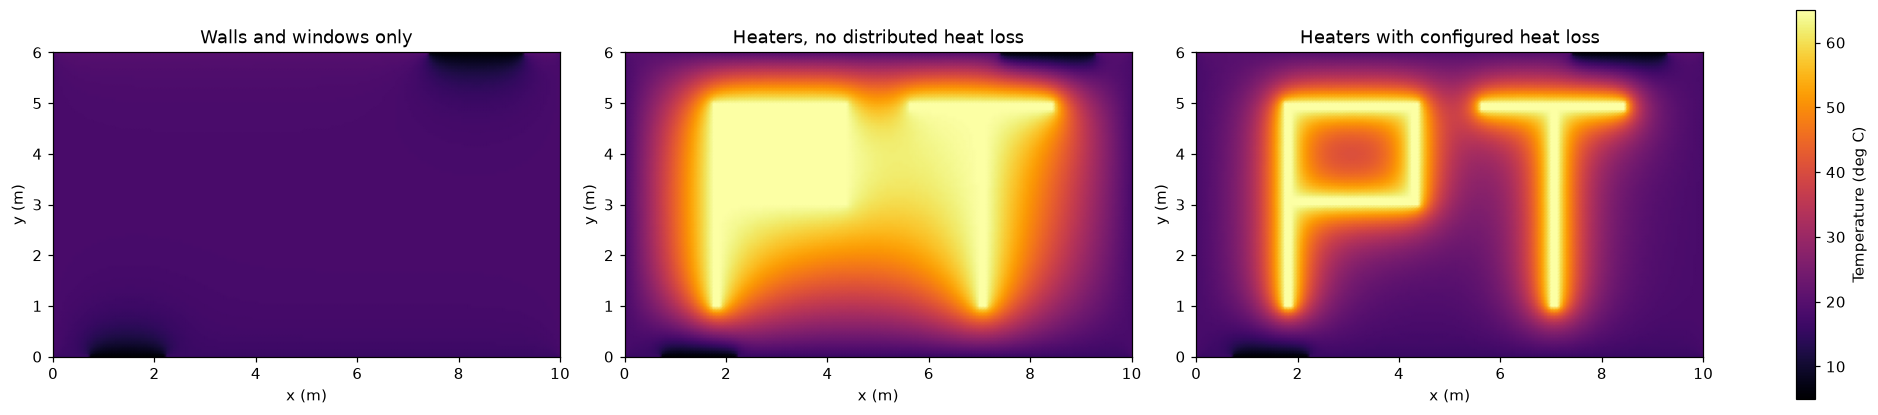

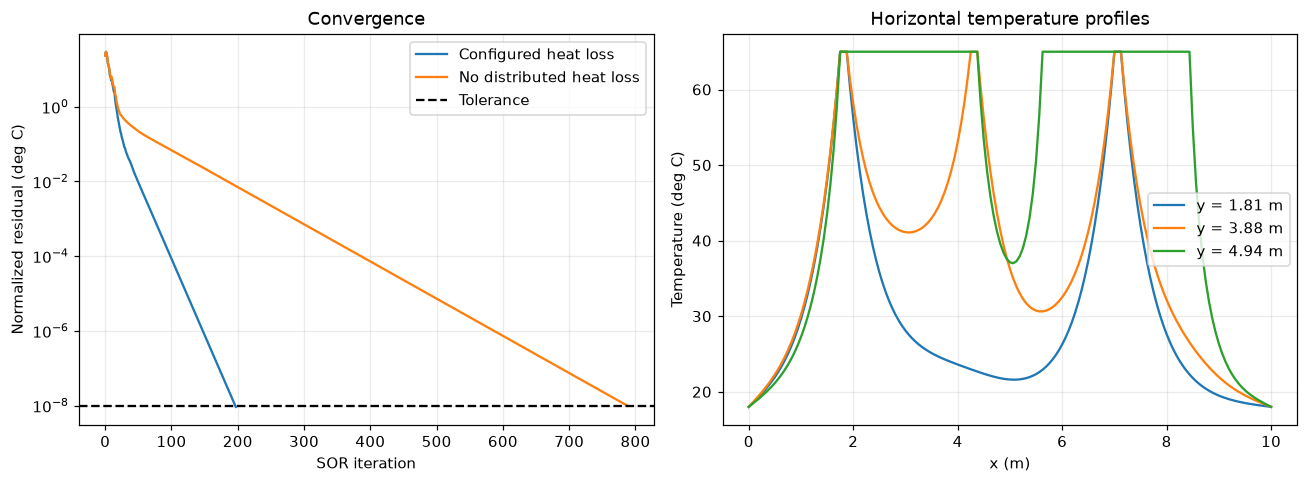

In [18]:
laplace_grid = build_heat_grid(dict(room, heat_loss=0.0), nx, ny, heaters, windows)
laplace_temperature, laplace_history = solve_room_heat(
    laplace_grid, omega=omega, tol=tolerance, limit=max_iterations)
baseline_grid = build_heat_grid(room, nx, ny, [], windows)
baseline_temperature, _ = solve_room_heat(
    baseline_grid, omega=omega, tol=tolerance, limit=max_iterations)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), layout="constrained")
for ax, field, title in zip(
        axes, (baseline_temperature, laplace_temperature, temperature),
        ("Walls and windows only", "Heaters, no distributed heat loss", "Heaters with configured heat loss")):
    image = draw_temperature(ax, grid, field, title, color_limits)
fig.colorbar(image, ax=axes, label="Temperature (deg C)", shrink=0.8)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].semilogy(np.maximum(history, np.finfo(float).tiny), label="Configured heat loss")
axes[0].semilogy(np.maximum(laplace_history, np.finfo(float).tiny), label="No distributed heat loss")
axes[0].axhline(tolerance, color="black", linestyle="--", label="Tolerance")
axes[0].set(xlabel="SOR iteration", ylabel="Normalized residual (deg C)", title="Convergence")
for fraction in (0.30, 0.65, 0.82):
    index = round(fraction * ny)
    axes[1].plot(grid['x'], temperature[index], label=f"y = {grid['y'][index]:.2f} m")
axes[1].set(xlabel="x (m)", ylabel="Temperature (deg C)", title="Horizontal temperature profiles")
for ax in axes:
    ax.grid(True, alpha=0.25)
    ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

#### Сравнение методов и сгущение сетки

Для Якоби, Зейделя и SOR используем одинаковую более грубую сетку,
начальное приближение и допуск. Это ускоряет сравнение. Если на грубой
сетке не разрешается маленький объект, увеличьте `comparison_nx` и
`comparison_ny` в ячейке ниже. Объекты не удаляются автоматически.

Затем удвоим число интервалов по каждой оси и сравним поля в общих свободных
узлах. На встроенных границах геометрия приближается узлами сетки: её края
могут смещаться на один шаг. Поэтому, в отличие от сравнения с рядом Фурье
для квадрата, здесь не заявляется строгий второй порядок сходимости.

Method          Iterations     Normalized residual (deg C)
Jacobi             1033       9.985e-09
Gauss-Seidel        537       9.967e-09
SOR                  98       9.841e-09
Grid refinement RMS difference at common free nodes: 0.6350 deg C
Grid refinement maximum difference at common free nodes: 5.2841 deg C


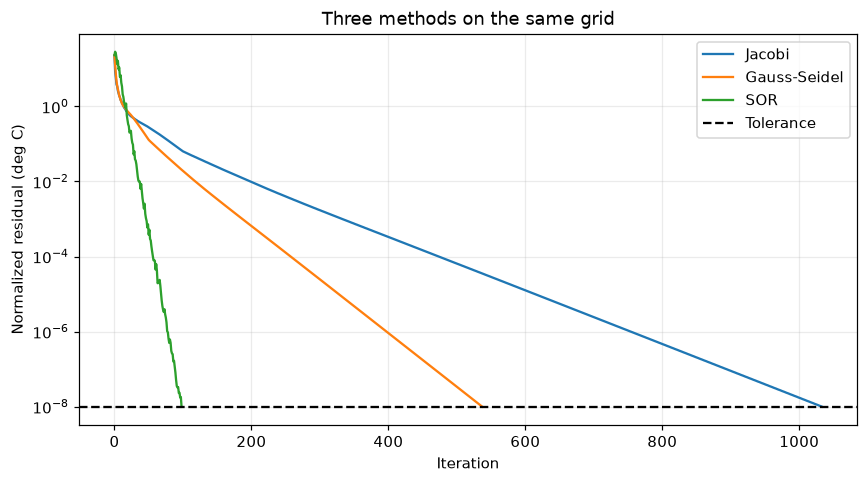

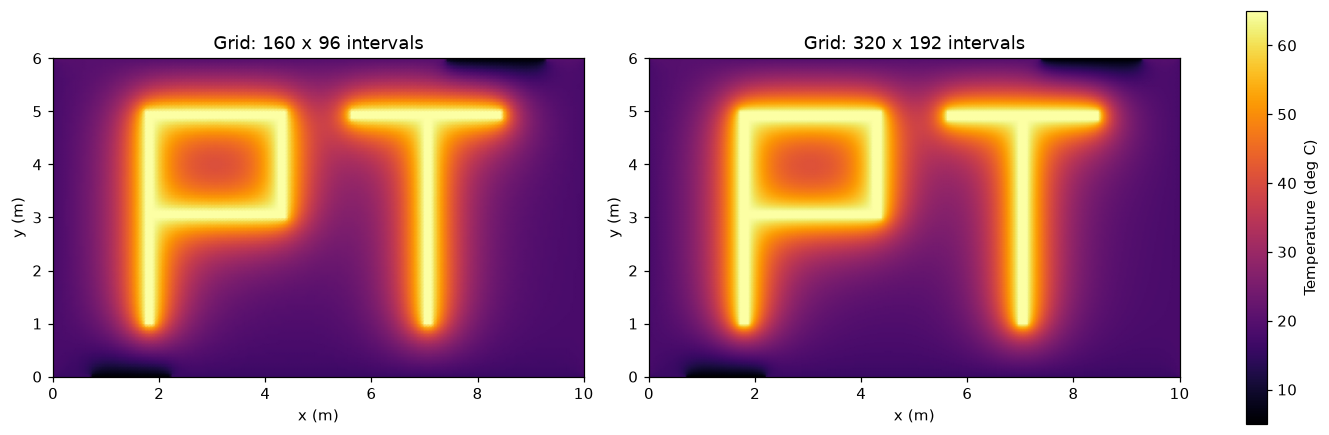

In [19]:
comparison_nx, comparison_ny = max(2, nx // 2), max(2, ny // 2)
comparison_grid = build_heat_grid(room, comparison_nx, comparison_ny, heaters, windows)
method_histories = {}
print("Method          Iterations     Normalized residual (deg C)")
for method in ("Jacobi", "Gauss-Seidel", "SOR"):
    _, residuals = solve_room_heat(comparison_grid, method, omega, tolerance, max_iterations)
    method_histories[method] = residuals
    print(f"{method:14s} {len(residuals) - 1:8d}       {residuals[-1]:.3e}")

fig, ax = plt.subplots(figsize=(8, 4.5))
for method, residuals in method_histories.items():
    ax.semilogy(np.maximum(residuals, np.finfo(float).tiny), label=method)
ax.set(xlabel="Iteration", ylabel="Normalized residual (deg C)",
       title="Three methods on the same grid")
ax.axhline(tolerance, color="black", linestyle="--", label="Tolerance")
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()
plt.close(fig)

# Geometry edges can move by a grid cell; report the difference, not an assumed order.
fine_grid = build_heat_grid(room, 2 * nx, 2 * ny, heaters, windows)
fine_temperature, _ = solve_room_heat(fine_grid, omega=omega, tol=tolerance, limit=max_iterations)
refinement_difference = fine_temperature[::2, ::2] - temperature
common_free = ~grid['fixed'] & ~fine_grid['fixed'][::2, ::2]
if common_free.any():
    print(f"Grid refinement RMS difference at common free nodes: "
          f"{np.sqrt(np.mean(refinement_difference[common_free]**2)):.4f} deg C")
    print(f"Grid refinement maximum difference at common free nodes: "
          f"{np.max(np.abs(refinement_difference[common_free])):.4f} deg C")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
draw_temperature(axes[0], grid, temperature,
                 f"Grid: {nx} x {ny} intervals", color_limits)
image = draw_temperature(axes[1], fine_grid, fine_temperature,
                         f"Grid: {2 * nx} x {2 * ny} intervals", color_limits)
fig.colorbar(image, ax=axes, label="Temperature (deg C)", shrink=0.85)
plt.show()
plt.close(fig)

#### Дополнительные эксперименты

- Задайте `windows = []`, чтобы исключить влияние окон.
- Уменьшите `room['heat_loss']` и проследите, как заполняется теплом просвет «Р».
- Увеличьте `room['conductivity']`, чтобы усилить размывание букв.
- Измените температуры стен и положение окон, чтобы изменить фон надписи.
- Задайте `custom_heaters`, чтобы заменить непрерывные полосы отдельными приборами.
- Увеличьте `nx` и `ny`, чтобы разрешить более тонкие полосы.

После каждого изменения выполните тетрадь сверху вниз. Сравнивайте поля
на одной цветовой шкале: иначе автоматический выбор цветов может скрыть
изменение температурного контраста.

## 5. Проверка реализации

### 5.1. Уравнение Лапласа в квадрате

Проверим фиксированные границы, сравним небольшую разностную систему
с независимой сборкой матрицы, проверим совпадение SOR при параметре 1
с методом Зейделя и явный отказ при слишком малом лимите итераций.
Проверим также значение ряда Фурье в центре и уменьшение ошибки при
сгущении сетки. Готовый решатель NumPy используется только для контроля.

In [20]:
# Assemble the small discrete problem independently of the iteration routines.
n = 4
initial = square_initial_temperature(n)
matrix = np.zeros(((n - 1)**2, (n - 1)**2))
rhs = np.zeros((n - 1)**2)
for j in range(1, n):
    for i in range(1, n):
        row = (j - 1) * (n - 1) + i - 1
        matrix[row, row] = 4
        for jj, ii in ((j, i - 1), (j, i + 1), (j - 1, i), (j + 1, i)):
            if 0 < jj < n and 0 < ii < n:
                column = (jj - 1) * (n - 1) + ii - 1
                matrix[row, column] = -1
            else:
                rhs[row] += initial[jj, ii]
expected = np.linalg.solve(matrix, rhs).reshape(n - 1, n - 1)
for method in square_methods:
    u, history = solve_square_heat(n, method, optimal_omega(n), tol=1e-12)
    np.testing.assert_allclose(u[1:-1, 1:-1], expected, atol=1e-10)
    np.testing.assert_array_equal(u[[0, -1], :], initial[[0, -1], :])
    np.testing.assert_array_equal(u[:, [0, -1]], initial[:, [0, -1]])
    assert history[-1] <= 1e-12
seidel_u, _ = solve_square_heat(6, "Gauss-Seidel")
sor_u, _ = solve_square_heat(6, "SOR", omega=1.0)
np.testing.assert_allclose(seidel_u, sor_u, atol=1e-12)
np.testing.assert_allclose(fourier_reference(square_length / 2, square_length / 2), (square_left + square_right + square_top + square_bottom) / 4)
assert grid_errors["SOR"][-1] < grid_errors["SOR"][0]
try:
    solve_square_heat(10, "Jacobi", limit=1)
except RuntimeError:
    pass
else:
    raise AssertionError("An unfinished iteration must be reported as a failure.")
print("All heat-equation checks passed.")

All heat-equation checks passed.


### 5.2. Комната с обогревателями и окнами

Независимое решение плотной системы проверяет разностную схему с разными
шагами по осям, потерями тепла, внутренним обогревателем и окном.
Дополнительно проверим постоянное решение, сохранение фиксированных узлов,
дискретный принцип максимума, совпадение трёх методов и обработку неверных
данных и несходимости. Для этих проверок используются собственные данные,
не зависящие от выбранных параметров основного эксперимента.

In [21]:
def dense_reference(grid):
    # Assemble the equations independently; use the full unnormalized operator.
    nodes = list(zip(*np.where(~grid['fixed'])))
    index = {node: position for position, node in enumerate(nodes)}
    matrix = np.zeros((len(nodes), len(nodes)))
    rhs = np.zeros(len(nodes))
    k, loss = grid['room']['conductivity'], grid['room']['heat_loss']
    for row, (j, i) in enumerate(nodes):
        matrix[row, row] = 2 * k / grid['dx']**2 + 2 * k / grid['dy']**2 + loss
        rhs[row] = loss * grid['room']['ambient']
        for jj, ii, weight in ((j, i - 1, k / grid['dx']**2), (j, i + 1, k / grid['dx']**2),
                               (j - 1, i, k / grid['dy']**2), (j + 1, i, k / grid['dy']**2)):
            if grid['fixed'][jj, ii]:
                rhs[row] += weight * grid['values'][jj, ii]
            else:
                matrix[row, index[jj, ii]] -= weight
    expected = grid['values'].copy()
    for node, value in zip(nodes, np.linalg.solve(matrix, rhs)):
        expected[node] = value
    return expected


test_room = dict(width=3.0, height=2.0, left=12.0, right=23.0, bottom=18.0,
                 top=27.0, ambient=16.0, conductivity=1.0, heat_loss=2.3)
test_heaters = [dict(name="Test heater", x_min=1.1, x_max=1.9,
                     y_min=0.6, y_max=1.4, temperature=60.0)]
test_windows = [dict(wall="top", start=0.4, end=1.4, temperature=4.0)]
for loss in (0.0, 2.3):
    test_grid = build_heat_grid(dict(test_room, heat_loss=loss), 6, 5, test_heaters, test_windows)
    expected = dense_reference(test_grid)
    for method in ("Jacobi", "Gauss-Seidel", "SOR"):
        actual, residuals = solve_room_heat(test_grid, method, omega=1.4, tol=1e-11)
        np.testing.assert_allclose(actual, expected, rtol=0, atol=1e-8)
        np.testing.assert_array_equal(actual[test_grid['fixed']], test_grid['values'][test_grid['fixed']])
        assert residuals[-1] <= 1e-11
        assert actual.min() >= 4.0 - 1e-8 and actual.max() <= 60.0 + 1e-8

uniform_room = dict(test_room, width=2, height=1, left=21, right=21,
                    bottom=21, top=21, ambient=21, heat_loss=4)
uniform_grid = build_heat_grid(uniform_room, 8, 6)
uniform_temperature, uniform_history = solve_room_heat(uniform_grid)
np.testing.assert_allclose(uniform_temperature, 21, rtol=0, atol=1e-12)
assert len(uniform_history) == 1

gs_temperature, gs_history = solve_room_heat(test_grid, "Gauss-Seidel", tol=1e-10)
sor_temperature, sor_history = solve_room_heat(test_grid, "SOR", omega=1, tol=1e-10)
np.testing.assert_array_equal(gs_temperature, sor_temperature)
np.testing.assert_array_equal(gs_history, sor_history)

# Verify all wall orientations and window overrides independently of the dense solve.
for wall in ("left", "right", "bottom", "top"):
    window_grid = build_heat_grid(test_room, 12, 10, windows=[dict(wall=wall, start=0.5, end=1.5, temperature=3)])
    assert np.count_nonzero(window_grid['window_mask']) > 0
    np.testing.assert_array_equal(window_grid['values'][window_grid['window_mask']], 3)
    assert np.all(window_grid['fixed'][window_grid['window_mask']])


def expect_error(error_type, operation):
    try:
        operation()
    except error_type:
        return
    raise AssertionError(f"Expected {error_type.__name__} was not raised.")


expect_error(ValueError, lambda: build_heat_grid(dict(test_room, width=-1), 6, 5))
expect_error(ValueError, lambda: build_heat_grid(dict(test_room, heat_loss=-1), 6, 5))
expect_error(ValueError, lambda: build_heat_grid(dict(test_room, top=np.nan), 6, 5))
expect_error(ValueError, lambda: build_heat_grid(test_room, True, 5))
expect_error(ValueError, lambda: build_heat_grid(test_room, 6, 2.5))
expect_error(ValueError, lambda: build_heat_grid(test_room, 6, 5, windows=[dict(wall='roof', start=0.2, end=1, temperature=3)]))
expect_error(ValueError, lambda: build_heat_grid(test_room, 6, 5, windows=[dict(wall='top', start=0, end=1, temperature=3)]))
expect_error(ValueError, lambda: build_heat_grid(test_room, 6, 5, windows=[dict(wall='top', start=0.1, end=0.2, temperature=3)]))
expect_error(ValueError, lambda: build_heat_grid(test_room, 6, 5, windows=[
    dict(wall='top', start=0.4, end=1.4, temperature=3), dict(wall='top', start=0.4, end=1.4, temperature=4)]))
for changes in (dict(x_min=-1), dict(x_min=0.1, x_max=0.2, y_min=0.1, y_max=0.2)):
    invalid_heater = dict(test_heaters[0], **changes)
    expect_error(ValueError, lambda: build_heat_grid(test_room, 6, 5, [invalid_heater]))
expect_error(ValueError, lambda: build_heat_grid(test_room, 6, 5, [
    test_heaters[0], dict(test_heaters[0], temperature=40)]))
expect_error(ValueError, lambda: solve_room_heat(test_grid, method="Unknown"))
expect_error(ValueError, lambda: solve_room_heat(test_grid, omega=2))
expect_error(ValueError, lambda: solve_room_heat(test_grid, tol=np.nan))
expect_error(ValueError, lambda: solve_room_heat(test_grid, limit=True))
expect_error(RuntimeError, lambda: solve_room_heat(test_grid, "Jacobi", limit=1))

np.testing.assert_array_equal(temperature[grid['fixed']], grid['values'][grid['fixed']])
assert temperature.min() >= color_min - 1e-5
assert temperature.max() <= color_max + 1e-5
print("All thermal-letter checks passed.")

All thermal-letter checks passed.


### 5.3. Согласованность двух постановок

При отключённых обогревателях, окнах и потерях тепла квадратная комната
должна давать тот же результат, что и задача А после перехода $T=100u$.
Сравним оба метода на небольшой сетке с независимыми исходными данными.
Эта проверка контролирует связь исходной лабораторной работы с её обобщением.

In [22]:
bridge_room = dict(width=0.1, height=0.1, left=100.0, top=200.0,
                   right=300.0, bottom=400.0, ambient=0.0,
                   conductivity=1.0, heat_loss=0.0)
bridge_grid = build_heat_grid(bridge_room, 8, 8)
bridge_temperature, _ = solve_room_heat(bridge_grid, omega=1.5, tol=1e-11)

# Use explicit independent boundary values, regardless of experiment settings.
bridge_square_grid = build_heat_grid(dict(bridge_room, left=1.0, top=2.0,
                                         right=3.0, bottom=4.0), 8, 8)
bridge_u = bridge_square_grid['values'].copy()
for _ in range(10000):
    sor_step(bridge_u, 1.5)
    if square_residual_norm(bridge_u) <= 1e-13:
        break
else:
    raise AssertionError("The square bridge calculation did not converge.")
np.testing.assert_allclose(bridge_temperature, 100 * bridge_u, rtol=0, atol=1e-8)
print("Both heat formulations agree when heaters, windows, and heat loss are disabled.")

Both heat formulations agree when heaters, windows, and heat loss are disabled.
